# XGLASS Inference Demo

This notebook provides a lightweight inference and visualization demo for XGLASS. It loads a trained checkpoint and demonstrates disease-conditioned slice scoring on a selected CT example. For full evaluation and quantitative benchmarking across datasets, please use the CLI evaluation script located at src/xglass/eval.py.

**Data access & licensing note.** XGLASS relies on several third-party datasets, including resources that require controlled access (e.g., PhysioNet/REFLACX). This notebook does **not** download any datasets, does not request credentials, and does not redistribute any raw or derived data. It assumes you have already obtained all required datasets through their official channels, agreed to the corresponding licenses/DUAs, and prepared the files locally by following `../data/README.md`.

Which includes:

* A **projection dataset** folder (created by `data/create_projection_dataset.py` / your projection script) that contains:

  * `manifest.csv`
  * `data/` with split subfolders (`train/`, `val/`, `test/`) and per-sample folders containing at least:

    * `aip_wide.png` (and optionally `aip_lung.png`, `aip_soft.png`, `bl_cxr.png`)
    * `gt_data.json`
    * `bbox_256.json`

* A **splits file** (`balanced_splits.json`) listing the CT identifiers (`ct_name`) used for `train/`, `val/`, `test`.

* A **gaze importance maps** directory containing the disease-specific `.npz` files expected by the loader (e.g. `gaze_raw_atelectasis.npz`, …).

Here is the expected local folder structure:

```text
data/
└── processed/
    ├── projection_dataset/
    │   ├── manifest.csv
    │   └── data/
    │       ├── train/
    │       │   └── <category_slug>/
    │       │       └── <ct_stem>/
    │       │           ├── aip_wide.png
    │       │           ├── gt_data.json
    │       │           └── bbox_256.json
    │       ├── val/ ...
    │       └── test/ ...
    ├── gaze_importance_maps/
    │   ├── gaze_raw_atelectasis.npz
    │   ├── gaze_raw_consolidation.npz
    │   ├── ...
    └── balanced_splits.json # Here define your desired dataset split in train val and test.

```

## Setup

### Step 1 — Dependencies

Create and activate a fresh environment, then install all required packages:

In [1]:
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


### Step 2 — Import XGLASS from `src/`

In [4]:
from pathlib import Path
import sys

p = Path.cwd().resolve()
while not (p / "src" / "xglass").is_dir():
    if p.parent == p:
        raise RuntimeError("Run the notebook from inside the XGLASS repository.")
    p = p.parent
REPO_ROOT = p
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from xglass.dataset import SliceDataModule
from xglass.model import SlicePredictor

DATA_ROOT = REPO_ROOT / "data"
PROJ_ROOT = DATA_ROOT / "processed" / "projection_dataset"
HEATMAP_DIR = DATA_ROOT / "processed" / "gaze_importance_maps"
SPLITS_JSON = REPO_ROOT / "splits" / "paper_splits.json"

for path in (PROJ_ROOT / "manifest.csv", HEATMAP_DIR, SPLITS_JSON):
    if not path.exists():
        raise FileNotFoundError(f"Prepare the local data first (data/README.md): {path}")
    print(path)


PROJ_ROOT  : C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\projection_dataset exists: True
manifest   : C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\projection_dataset\manifest.csv exists: True
HEATMAP_DIR: C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\gaze_importance_maps exists: True
SPLITS_JSON: C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\balanced_splits.json exists: True
xglass imported from: C:\Users\gl-mi\Documents\GitHub\XGLASS\src\xglass\__init__.py


c:\Users\gl-mi\Documents\GitHub\XGLASS\.conda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inference

### Step 1 — Load the projection dataset and pick one example

In [8]:
import random
import torch
from xglass.dataset import SliceDataModule

# DataModule (same settings as training)
dm = SliceDataModule(
    data_root=str(PROJ_ROOT),
    heatmap_dir=str(HEATMAP_DIR),
    splits_json=str(SPLITS_JSON),
    projection_type="aip_wide",
    blend_alpha=0.75,
    target_mode="area",
    batch_size=1,
    num_workers=0,
)

dm.setup(stage="test")

n = len(dm.test_dataset)
if n == 0:
    raise RuntimeError("Test split is empty. Put at least one ct_name into 'test' in balanced_splits.json.")

sample_idx = random.randrange(n)
img, gt_vec, gt_order = dm.test_dataset[sample_idx]   # img: [3,256,256], gt_vec: [240]

print(f"Selected test sample idx: {sample_idx} / {n-1}")
print("img   :", tuple(img.shape), img.dtype)
print("gt_vec:", tuple(gt_vec.shape), gt_vec.dtype)

# (Optional) try to print ct_name/category if available
try:
    row = dm.test_df.reset_index(drop=True).iloc[sample_idx]
    print("ct_name :", row.get("ct_name", "N/A"))
    print("category:", row.get("category", "N/A"))
except Exception:
    row = None



Pre-loading heatmaps from C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\gaze_importance_maps...
Pre-loading heatmaps from C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\gaze_importance_maps...
Pre-loading heatmaps from C:\Users\gl-mi\Documents\GitHub\XGLASS\data\processed\gaze_importance_maps...
Dataset setup complete:
  Train samples: 1
  Val samples:   1
  Test samples:  1
Selected test sample idx: 0 / 0
img   : (3, 256, 256) torch.float32
gt_vec: (240,) torch.float32
ct_name : train_1381_c_1.nii.gz
category: Groundglass opacity


### Step 2 — Run inference (slice scoring)

In [16]:
from pathlib import Path
import torch
from xglass.model import SlicePredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# --- pick newest checkpoint file in the experiment folder ---
ckpt_dir = REPO_ROOT / "checkpoints" / "vit_base_patch16_224.augreg_in21k_aip_wide_alpha0.75"
ckpt_files = sorted(ckpt_dir.glob("*.ckpt"), key=lambda p: p.stat().st_mtime, reverse=True)
if not ckpt_files:
    raise FileNotFoundError(f"No .ckpt files found in: {ckpt_dir}")

ckpt_path = ckpt_files[0]
print("Using checkpoint:", ckpt_path)

# --- load model ---
model = SlicePredictor.load_from_checkpoint(str(ckpt_path), cache_dir=None)
model.to(device).eval()

# --- forward ---
img_1 = img.unsqueeze(0).to(device)   # [1,3,256,256]

with torch.no_grad():
    scores = model(img_1)             # [1,240] (expected)

print("Model output size:", tuple(scores.shape))

scores = scores[0]                    # [240]
pred_slice = int(torch.argmax(scores).item())

topk = 10
vals, idx = torch.topk(scores, k=topk)

print("Predicted top-1 slice:", pred_slice)
print("Top-K indices:", idx.cpu().tolist())


Device: cpu
Using checkpoint: C:\Users\gl-mi\Documents\GitHub\XGLASS\checkpoints\vit_base_patch16_224.augreg_in21k_aip_wide_alpha0.75\epoch=06-val_auc_epoch=0.7957-val_spearman_epoch=0.3219.ckpt
[Model Log] Attempting to create model: vit_base_patch16_224.augreg_in21k
[Model Log] Using cache directory: None
[Model Log] Successfully created backbone.
[Model Log] Backbone is FINETUNED. Training in end-to-end mode.
[Model Log] Creating resize transform for (256, 256) -> (224, 224)
Model output size: (1, 240)
Predicted top-1 slice: 85
Top-K indices: [85, 81, 79, 88, 76, 78, 74, 80, 96, 75]


### Step 3 — Plot results

This next cell visualizes the end-to-end inference output for a single CT example:

- **Left:** the model input image (CT projection fused with the disease-conditioned gaze prior).
- **Middle:** the **GT slice relevance distribution** (weak slice-level target) with a cyan dashed line indicating the **predicted top-1 slice index**.
- **Right:** the corresponding **axial CT slice** at the predicted index (mapped back to the resampled full CT volume).

If you cannot reproduce the plot locally (e.g., missing access to the underlying datasets), the figure below shows an example output produced with our local setup:

<img src="./demo_outputs/train_1381_c_1_Groundglass_opacity_pred85.png" style="max-width:70%;">

C:\Users\gl-mi\AppData\Local\Temp\ipykernel_43392\1157961944.py:129: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.0, 1, 0.92], pad=0.2, w_pad=0.0, h_pad=0.0)


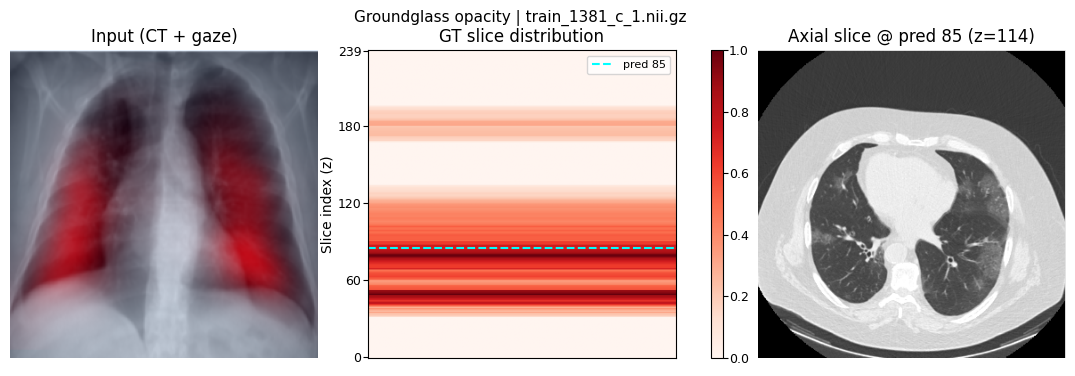

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json

import nibabel as nib
from nibabel.processing import resample_to_output

# ---- CONFIG ----
RAW_CT_ROOT = REPO_ROOT / "data" / "ReXGroundingCT" / "cts"
# Also support the compact local example layout.
if not (RAW_CT_ROOT / str(row["ct_name"])).is_file():
    RAW_CT_ROOT = REPO_ROOT / "data" / "processed" / "cts"
TARGET_SPACING_MM = 1.25                                     # must match preprocessing

# ---- Metadata ----
if row is None:
    raise RuntimeError("Need 'row' (from dm.test_df.iloc[idx]) to get ct_name/category and bbox_256.json path.")

ct_name = str(row["ct_name"])
category = str(row.get("category", "unknown-category"))

# ---- GT square heatmap ----
gt_np = gt_vec.detach().cpu().numpy().astype(np.float32)  # [S]
S = gt_np.shape[0]
gt_square = np.repeat(gt_np.reshape(S, 1), repeats=S, axis=1)  # [S,S]

def tensor_to_rgb01(_model, batch):
    image = batch[0].detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    return np.clip(image * std + mean, 0, 1)


# ---- Input projection (CT + gaze) ----
img_np = tensor_to_rgb01(model, img.unsqueeze(0))  # HxWx3 in [0,1]

# ---- Map predicted slice -> absolute z in iso volume (NO x/y crop for display) ----
bbox_rel = row.get("bbox_json_path", None)
if bbox_rel is None:
    data_rel = row.get("data_path", None)
    if data_rel is None:
        raise KeyError("Could not find 'bbox_json_path' or 'data_path' in manifest/test_df.")
    bbox_rel = Path(data_rel) / "bbox_256.json"
else:
    bbox_rel = Path(bbox_rel)

bbox_path = (PROJ_ROOT / bbox_rel).resolve()
if not bbox_path.exists():
    raise FileNotFoundError(f"bbox_256.json not found at: {bbox_path}")

bbox_data = json.loads(bbox_path.read_text(encoding="utf-8"))
crop = bbox_data.get("crop_window_iso", None)
if crop is None or len(crop) != 4:
    raise ValueError("bbox_256.json missing valid 'crop_window_iso'=[x0_crop,x1_crop,z0,z1].")

z0_crop = int(crop[2])

ct_path = (RAW_CT_ROOT / ct_name).resolve()
if not ct_path.exists():
    raise FileNotFoundError(
        f"Raw CT not found: {ct_path}\n"
        f"Set RAW_CT_ROOT to the folder containing ct_name files."
    )

ct_native = nib.load(str(ct_path))
ct_ras = nib.as_closest_canonical(ct_native)
ct_iso = resample_to_output(ct_ras, voxel_sizes=(TARGET_SPACING_MM,) * 3, order=1)
vol = ct_iso.get_fdata().astype(np.float32)  # [X,Y,Z]

z_abs = z0_crop + int(pred_slice)
if not (0 <= z_abs < vol.shape[2]):
    raise ValueError(f"z_abs out of bounds: {z_abs} (vol Z={vol.shape[2]}). Check spacing/crop_window_iso.")

axial = vol[:, :, z_abs]  # FULL axial slice

def window_hu(img2d, center=-600, width=1500):
    lo, hi = center - width / 2, center + width / 2
    img2d = np.clip(img2d, lo, hi)
    return (img2d - lo) / (hi - lo + 1e-6)

axial_disp = window_hu(axial, center=-600, width=1500)
axial_disp = np.flipud(axial_disp.T)  # display orientation

# ---- Plot layout: make colorbar "hug" the GT plot ----
fig = plt.figure(figsize=(14, 4))

# width_ratios:
#   col0 = input
#   col1 = GT
#   col2 = colorbar (very thin) -> makes it close to GT
#   col3 = axial
gs = fig.add_gridspec(
    1, 4,
    width_ratios=[1.0, 1.0, 0.035, 1.0],  # small cbar column = small gap
    wspace=0.08,                           # small but enough to avoid label overlap
)

ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])
ax2 = fig.add_subplot(gs[0, 3])

# Panel 1: input
ax0.imshow(img_np)
ax0.set_title("Input (CT + gaze)")
ax0.axis("off")

# Panel 2: GT slice distribution
im = ax1.imshow(
    gt_square,
    cmap="Reds",
    origin="lower",
    vmin=0.0,
    vmax=1.0,
    aspect="equal",
)
ax1.axhline(pred_slice, color="cyan", linewidth=1.5, linestyle="--", label=f"pred {pred_slice}")
ax1.set_title("GT slice distribution")
ax1.set_xticks([])
ax1.set_ylabel("Slice index (z)", labelpad=2)
ax1.tick_params(axis="y", labelsize=9, pad=1)
ax1.set_yticks([0, S // 4, S // 2, 3 * S // 4, S - 1])
ax1.set_yticklabels([0, S // 4, S // 2, 3 * S // 4, S - 1])
ax1.legend(loc="upper right", fontsize=8)

# Colorbar: dedicated axis, tight to GT
cb = fig.colorbar(im, cax=cax)
cb.ax.tick_params(labelsize=9, pad=1)

# Panel 3: axial slice
ax2.imshow(axial_disp, cmap="gray")
ax2.set_title(f"Axial slice @ pred {pred_slice} (z={z_abs})")
ax2.axis("off")

fig.suptitle(f"{category} | {ct_name}", fontsize=11)

# Keep it tight, but avoid overlaps
fig.tight_layout(rect=[0, 0.0, 1, 0.92], pad=0.2, w_pad=0.0, h_pad=0.0)
plt.show()

